# Why does learned temporal cost do worse than MSE?

On the five evaluation banks, using the temporal cost caused worse actions to be selected than just using plain MSE: regret 13.46 vs 5.30 (`docs/pusht_temporal_cost.md`). This notebook is an analysis script to try and figure out why.

**The two costs.** Both take a candidate state and a goal photo and return a number (the cost). The planner chooses the lowest action cost.

- **MSE** is the mean squared difference between the candidate's DINO-WM features and the goal photo's features.
- **Temporal** is a small trained network which predicts how many model steps separate two frames of a recorded episode.

**The questions**, we will answer:

| Step | Question | Why it matters |
|---|---|---|
| 1 | Is the gap visible on fresh banks? | Everything below explains this gap |
| 2 | Does the cost count steps correctly on episodes it never trained on? | If not, its score is unreliable before planning even starts |
| 3 | How varied is the training data? | A cost can only generalize as far as its data varies |
| 4 | Is it worse everywhere, or only among candidates near the goal? | Picking the best candidate depends on the near ones |
| 5 | Does its score follow the T or the agent? | The T is what the task scores; the agent is only in the photo by chance |
| 6 | Does it fail because it sees predicted features instead of real ones? | It was trained only on real ones |
| 7 | Would it work if the goal photo's agent were in the right place? | Tests whether the goal photo is the real cause |

**Banks.** This notebook uses dev banks 20261301–03 (not 20261008–12, which is for eval).

This notebook needs a GPU, `data/pusht_noise`, the DINO-WM checkpoint and the trained cost, and takes about five minutes.

## Setup

In [1]:
%%capture
import logging, pickle, sys, warnings
from pathlib import Path

import decord
import gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT / "code"))
logging.disable(logging.WARNING)
warnings.filterwarnings("ignore")

from experiments.run_pusht_multi_goal_probe import _render_states, generate_action_bank, predict_action_candidates
from experiments.run_pusht_temporal_probe import load_cost, mse_costs, temporal_costs
from experiments.summarize_pusht_multi_goal import hierarchical_interval
from experiments.train_pusht_temporal_cost import strided_frames
from jepa_planning.model import load_world_model
from jepa_planning.pusht_multi_goal import encode_observations, physical_errors, state_from
from jepa_planning.temporal_cost import photo_agreement

DEV_BANKS = [20261301, 20261302, 20261303]
COST_PATH = ROOT / "results/pusht_temporal_cost/seed_20261201/temporal_cost.pt"
device = torch.device("cuda")

model = load_world_model("pusht", "cuda").requires_grad_(False).eval()
cost = load_cost(COST_PATH, device)
train_config = torch.load(COST_PATH, map_location="cpu", weights_only=True)["config"]
METHODS = {"mse": mse_costs, "temporal": lambda x, g: temporal_costs(cost, x, g)}

## What one probe task looks like

Each bank has 30 tasks. EAch task has:

- **Start state:** the T with the agent next to it.
- **Candidates:** 64 random action chunks, each run for one model step. Every candidate ends in a different state.
- **Target T pose:** near the candidate that moved the T the most, plus a little noise.
- **Goal photos:** 8 images of the T at that pose. The agent position changes randomly between these images.

The planner never sees the true poses. It scores each candidate against one goal photo at a time, and repeats that for all 8 photos. We know the true poses, so we can grade its choice.

`score_bank()` below does that scoring in four combinations of input:

| Input | Options |
|---|---|
| Candidate features (`source`) | `predicted`: what the world model imagines, which is what the planner uses. `actual`: the encoded simulator frame |
| Goal photos (`goal`) | `random_agent`: the 8 normal photos. `matched_agent`: one extra photo with the agent placed where the best candidate's agent ended up |

The last two options exist only for steps 6 and 7.

In [2]:
def score_bank(seed):
    # Return all candidate costs for one bank, plus the true states needed to grade them.
    config = yaml.safe_load((ROOT / "code/configs/pusht_multi_goal_probe.yaml").read_text())
    config["seed"] = seed
    torch.manual_seed(seed)
    action_mean = model.preprocessor.action_mean.cpu().numpy()
    action_std = model.preprocessor.action_std.cpu().numpy()
    bank = generate_action_bank(config, action_mean, action_std)
    C, K, batch = config["candidates_per_task"], config["goals_per_task"], config["batch_size"]

    goals = encode_observations(model, bank["goal_frames"], bank["goal_proprioception"], batch)
    features = {
        "predicted": predict_action_candidates(model, bank, config),
        "actual": encode_observations(model, bank["candidate_frames"], bank["candidate_proprioception"], batch),
    }

    # The extra goal photo: the same target T, with the agent where the best candidate's agent is.
    matched_states = []
    for task in range(config["tasks"]):
        rows = slice(task * C, (task + 1) * C)
        best = physical_errors(bank["candidate_poses"][rows], bank["goal_poses"][task])[2].argmin()
        matched_states.append(state_from(bank["candidate_states"][rows][best, :2], bank["goal_poses"][task]))
    matched_frames, matched_proprio = _render_states(np.stack(matched_states))
    matched_goals = encode_observations(model, matched_frames, matched_proprio, batch)

    tasks = []
    for task in range(config["tasks"]):
        rows, photos = slice(task * C, (task + 1) * C), slice(task * K, (task + 1) * K)
        entry = {
            "seed": seed,
            "task": task,
            "start": bank["initial_states"][task],
            "poses": bank["candidate_poses"][rows],
            "agents": bank["candidate_states"][rows][:, :2],
            "goal_pose": bank["goal_poses"][task],
            "photo_agents": {"random_agent": bank["goal_proprioception"][photos, :2], "matched_agent": matched_proprio[task : task + 1, :2]},
            "costs": {},
        }
        for source, feats in features.items():
            for method, score in METHODS.items():
                entry["costs"][source, "random_agent", method] = score(feats[rows], goals[photos])
                entry["costs"][source, "matched_agent", method] = score(feats[rows], matched_goals[task : task + 1])
        tasks.append(entry)
    pictures = {key: bank[key] for key in ("initial_frames", "goal_frames", "candidate_frames")}
    pictures["matched_frames"] = matched_frames
    return tasks, pictures, config


tasks, pictures = [], None
for seed in DEV_BANKS:
    bank_tasks, bank_pictures, config = score_bank(seed)
    tasks += bank_tasks
    pictures = pictures or bank_pictures
C, K = config["candidates_per_task"], config["goals_per_task"]
print(f"{len(tasks)} tasks, {C} candidates and {K} goal photos each")

90 tasks, 64 candidates and 8 goal photos each


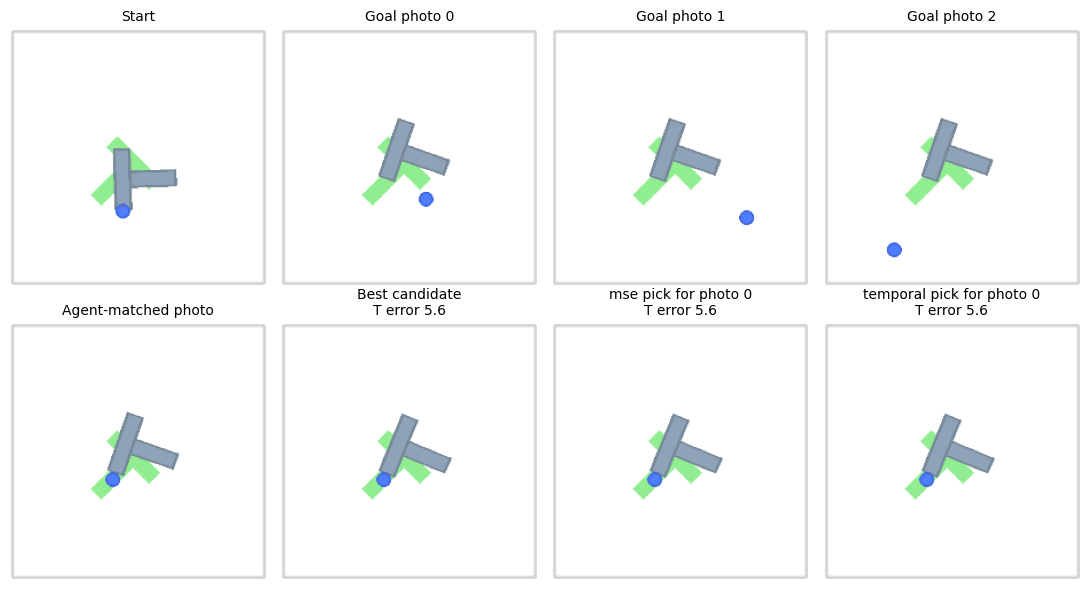

In [3]:
example = tasks[0]
t_error = physical_errors(example["poses"], example["goal_pose"])[2]
choice = {m: example["costs"]["predicted", "random_agent", m][:, 0].argmin() for m in METHODS}

panels = [("Start", pictures["initial_frames"][0])]
panels += [(f"Goal photo {i}", pictures["goal_frames"][i]) for i in range(3)]
panels += [("Agent-matched photo", pictures["matched_frames"][0])]
panels += [(f"Best candidate\nT error {t_error.min():.1f}", pictures["candidate_frames"][t_error.argmin()])]
panels += [(f"{m} pick for photo 0\nT error {t_error[c]:.1f}", pictures["candidate_frames"][c]) for m, c in choice.items()]

figure, axes = plt.subplots(2, 4, figsize=(11, 6))
for axis, (title, image) in zip(axes.flat, panels):
    axis.imshow(image)
    axis.set_title(title, fontsize=10)
    axis.axis("off")
plt.tight_layout()
plt.show()

## How each number is calculated

We compute metrics for one goal image at a time, then average over photos and tasks.

T error measures how far a candidate's T is from the target T, in pixels, with one radian of rotation counted as 50 pixels:

$$\text{T error} = \sqrt{\text{position error}^2 + (50 \cdot \text{angle error})^2}$$

Lower is better. This comes from `physical_errors` and ignores the agent completely.

| Name | How it is calculated | Good value |
|---|---|---|
| `regret` | T error of the chosen candidate, minus the T error of the best of the 64 | 0 |
| `success` | Chosen candidate is within 20 pixels and 20° of the target | 1 |
| `rank_all` | Spearman correlation between the cost and T error over all 64 candidates. 1 means the cost orders them exactly as T error does | 1 |
| `rank_near` | The same correlation over only the 16 candidates with the lowest T error | 1 |
| `agreement` | Share of photo pairs in a task that choose the same candidate. The T target is identical across photos, so ideally they always agree | 1 |
| `agent_distance` | Distance between each candidate's agent and the agent in the goal photo, in pixels | — |
| `t_weight`, `agent_weight`, `r2` | Explained in step 5 | — |

In [4]:
def z_score(values):
    return (values - values.mean()) / (values.std() + 1e-9)


def spearman(first, second):
    value = spearmanr(first, second).statistic
    return 0.0 if not np.isfinite(value) else float(value)


def grade_photo(costs, poses, agents, goal_pose, photo_agent):
    # Grade one goal photo. `costs` has one value per candidate.
    _, _, t_err, success = physical_errors(poses, goal_pose)
    chosen = costs.argmin()
    near = np.argsort(t_err)[:16]
    agent_distance = np.linalg.norm(agents - photo_agent, axis=1)

    # Step 5: fit z(cost) = t_weight * z(T error) + agent_weight * z(agent distance).
    inputs = np.c_[z_score(t_err), z_score(agent_distance)]
    target = z_score(costs)
    weights = np.linalg.lstsq(inputs, target, rcond=None)[0]
    r2 = 1 - np.mean((target - inputs @ weights) ** 2) / np.mean(target**2)

    return {
        "regret": t_err[chosen] - t_err.min(),
        "success": float(success[chosen]),
        "rank_all": spearman(costs, t_err),
        "rank_near": spearman(costs[near], t_err[near]),
        "t_weight": weights[0],
        "agent_weight": weights[1],
        "r2": r2,
        "mean_cost": costs.mean(),
    }


rows = []
for task in tasks:
    for (source, goal, method), costs in task["costs"].items():
        graded = [
            grade_photo(costs[:, k], task["poses"], task["agents"], task["goal_pose"], task["photo_agents"][goal][k])
            for k in range(costs.shape[1])
        ]
        row = pd.DataFrame(graded).mean().to_dict()
        row["agreement"] = photo_agreement(costs) if costs.shape[1] > 1 else np.nan
        rows.append({"seed": task["seed"], "task": task["task"], "source": source, "goal": goal, "method": method, **row})
results = pd.DataFrame(rows)  # one row per task, averaged over its photos


def compare(metrics, source="predicted", goal="random_agent", lower_is_better=("regret",)):
    # Temporal minus MSE per task, with a 95% interval that resamples banks, then tasks.
    # The sign is flipped where lower is better, so a positive difference favors temporal.
    # With three banks these intervals are coarse.
    rng = np.random.default_rng(20261301)
    subset = results[(results.source == source) & (results.goal == goal)]
    pivot = subset.pivot(index=["seed", "task"], columns="method")
    table = []
    for metric in metrics:
        sign = -1 if metric in lower_is_better else 1
        difference = sign * (pivot[metric]["temporal"] - pivot[metric]["mse"])
        paired = [{"seed": seed, "value": value} for (seed, _), value in difference.items()]
        mean, low, high = hierarchical_interval(paired, "value", rng, 10_000)
        per_bank = difference.groupby("seed").mean()
        table.append({
            "metric": metric,
            "mse": pivot[metric]["mse"].mean(),
            "temporal": pivot[metric]["temporal"].mean(),
            "favors temporal by": mean,
            "95% low": low,
            "95% high": high,
            "banks favoring temporal": f"{(per_bank > 0).sum()} of {len(per_bank)}",
        })
    return pd.DataFrame(table).set_index("metric").round(3)

## Step 1: Is the gap visible on these banks?

In [5]:
compare(["regret", "success", "rank_all", "agreement"])

,mse,temporal,favors temporal by,95% low,95% high,banks favoring temporal
metric,,,,,,
regret,7.295,10.408,-3.114,-6.595,0.889,1 of 3
success,0.806,0.640,-0.165,-0.264,-0.060,0 of 3
rank_all,0.532,0.503,-0.029,-0.101,0.035,0 of 3
agreement,0.691,0.574,-0.117,-0.201,-0.035,0 of 3


Temporal loses on success by 0.166 and agreement by 0.117 in all three banks. Regret is worse on average (10.4 vs 7.3), but one bank came out level and the interval includes zero, so the gap is smaller and less certain here than on the evaluation banks (−8.2). Since banks differ a lot, we should expect some noise in metrics.

`agreement` is the number the temporal cost was meant to improve, and it is lower than MSE's.

## Step 2: Does it count steps correctly on episodes it never trained on?

Let's forget planning for a moment and use the task the cost was trained for. Take every pair of frames in an episode (up to 24 steps apart), where the answer is simply the gap between them, and and check if our cost function can predict this gap well.

We do this on the 21 validation episodes (never trained on) and on 21 training episodes spaced evenly through the training set. We also try frames from two different episodes, which training labels as 24.

If predictions are good on training episodes but poor on validation episodes, the cost has learned something specific to its training episodes rather than a general sense of time.

We also measure ordering accuracy: take two frames at different distances from the same goal frame. How often does the cost give the farther frame a higher score? This relates closer to the logic that the planner uses.

In [6]:
@torch.inference_mode()
def encode_episodes(split, episodes):
    # Encode strided frames exactly as training did. Returns features and frames per episode.
    folder = ROOT / "data/pusht_noise" / split
    lengths = list(pickle.load((folder / "seq_lengths.pkl").open("rb")))
    features, counts = [], []
    for episode in episodes:
        frames = strided_frames(int(lengths[episode]), train_config["frame_stride"]).tolist()
        video = decord.VideoReader(str(folder / "obses" / f"episode_{episode:03d}.mp4"), num_threads=1)
        video = torch.from_numpy(video.get_batch(frames).asnumpy()).permute(0, 3, 1, 2)[:, None]
        features.append(model.encode(video)[:, -1].flatten(start_dim=1).half().float().cpu())
        counts.append(len(frames))
    return torch.cat(features), np.asarray(counts)


@torch.inference_mode()
def recorded_pairs(split, episodes):
    # Score every same-episode frame pair within max_gap, and cross-episode pairs.
    max_gap = train_config["max_gap"]
    features, counts = encode_episodes(split, episodes)
    starts = np.concatenate(([0], np.cumsum(counts)[:-1]))

    pairs, ordering = [], {1: [], 2: [], 4: []}
    for start, count in zip(starts, counts):
        episode = features[start : start + count].to(device)
        for goal in range(count):
            first = max(0, goal - max_gap)
            predicted = cost(episode[first : goal + 1], episode[goal : goal + 1]).cpu().numpy()
            gaps = goal - np.arange(first, goal + 1)  # descending
            pairs += [{"gap": int(g), "predicted": float(p)} for g, p in zip(gaps, predicted)]
            for difference, correct in ordering.items():
                correct += list(predicted[:-difference] > predicted[difference:])

    rng = np.random.default_rng(0)
    episode_of = np.repeat(np.arange(len(counts)), counts)
    first, second = rng.integers(len(features), size=(2, 2000))
    keep = episode_of[first] != episode_of[second]
    other = cost(features[first[keep]].to(device), features[second[keep]].to(device)).cpu().numpy()
    return pd.DataFrame(pairs), {k: float(np.mean(v)) for k, v in ordering.items()}, float(other.mean())


spaced = np.linspace(0, 18_684, 21).astype(int).tolist()
recorded = {"train": recorded_pairs("train", spaced), "val": recorded_pairs("val", range(21))}
shown_gaps = [1, 2, 4, 8, 12, 16, 20]
table = {}
for split, (pairs, _, _) in recorded.items():
    pairs = pairs.assign(error=(pairs.predicted - pairs.gap).abs())
    grouped = pairs[pairs.gap.isin(shown_gaps)].groupby("gap")
    table[f"{split}: mean predicted"] = grouped.predicted.mean()
    table[f"{split}: spread (sd)"] = grouped.predicted.std()
    table[f"{split}: mean abs error"] = grouped.error.mean()
display(pd.DataFrame(table).round(2))

display(pd.DataFrame(
    {split: {f"ordering accuracy, {k} step(s) apart": v for k, v in item[1].items()} | {"mean prediction, different episodes (label 24)": item[2]}
     for split, item in recorded.items()}
).round(3))

,train: mean predicted,train: spread (sd),train: mean abs error,val: mean predicted,val: spread (sd),val: mean abs error
gap,,,,,,
1,1.25,1.02,0.71,1.62,2.12,1.13
2,2.59,1.57,1.12,3.42,3.40,1.91
4,4.75,2.28,1.46,6.41,4.45,3.07
8,8.64,2.78,1.82,12.08,5.71,5.15
12,12.21,3.33,2.34,16.55,5.52,5.93
16,15.83,3.85,2.52,19.11,4.63,5.02
20,19.40,4.22,2.45,20.14,3.60,3.19


,train,val
"ordering accuracy, 1 step(s) apart",0.842,0.804
"ordering accuracy, 2 step(s) apart",0.892,0.855
"ordering accuracy, 4 step(s) apart",0.936,0.913
"mean prediction, different episodes (label 24)",22.765,22.157


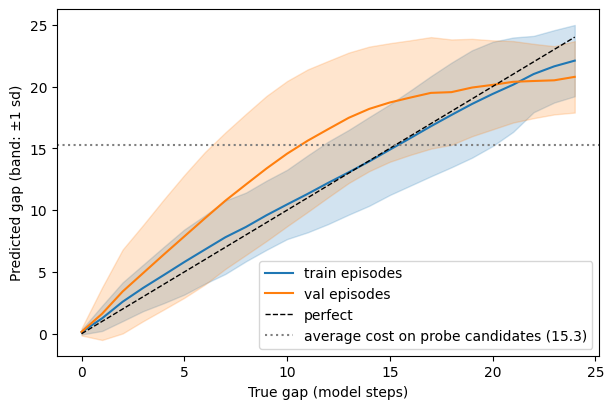

In [7]:
probe_mean = results[(results.source == "predicted") & (results.goal == "random_agent") & (results.method == "temporal")].mean_cost.mean()

figure, axis = plt.subplots(figsize=(7, 4.5))
for split, color in (("train", "tab:blue"), ("val", "tab:orange")):
    stats = recorded[split][0].groupby("gap").predicted.agg(["mean", "std", "count"])
    stats = stats[stats["count"] >= 20]
    axis.plot(stats.index, stats["mean"], color=color, label=f"{split} episodes")
    axis.fill_between(stats.index, stats["mean"] - stats["std"], stats["mean"] + stats["std"], color=color, alpha=0.2)
axis.plot([0, 24], [0, 24], "k--", linewidth=1, label="perfect")
axis.axhline(probe_mean, color="gray", linestyle=":", label=f"average cost on probe candidates ({probe_mean:.1f})")
axis.set_xlabel("True gap (model steps)")
axis.set_ylabel("Predicted gap (band: ±1 sd)")
axis.legend()
plt.show()

- On training episodes, predictions are quite close to the true gap, with errors of about 1–2.5 steps.
- On validation episodes, predictions are high for most of our tested gap range (up until a gap of around 20 steps). Errors reach about 6 steps, and the spread is larger, especially at short gaps.
- Ordering: the gap between training and validation is small (84% vs 80% one step apart). Ordering frames one step apart is imperfect even on training episodes.

This shows us that generalization is a problem. Additionally, there is a second problem too: the cost is not discriminant at one step, which is a problem since all 64 candidates are only one model step from the start.

The dotted line shows that probe costs average about 15. These goal photos are not in the same episode as the candidate, so this doesn't translate directly into a step count. It does suggest the cost is working well away from the short gaps where it is most precise.

## Step 3: How varied is the training data?

The training set has 18,685 episodes. But an episode only adds variety if it shows a new situation, so we count how many different starting states there are. The state is the agent's position plus the T's position and angle. Two episodes with the same start count as one scene.

We then check how far the validation and probe starts are from the nearest training scene using the T error formula.

If there are far fewer scenes than episodes, the cost has really seen only that many situations, and new scenes would be unfamiliar to it.

,value
training episodes,18685
distinct scenes,185
median episodes per scene,101.0
fewest / most episodes per scene,101 / 101
"scenes in the first 2,000 episodes",20
scenes in the 21 spaced episodes (step 2),21
scenes in the first 21 episodes,1
median distance to nearest scene: another training scene,30.2
median distance to nearest scene: validation start,29.7
median distance to nearest scene: probe start,33.4


T position 50 frames in, across the first 21 episodes (one scene): sd [0.2 0.3] pixels


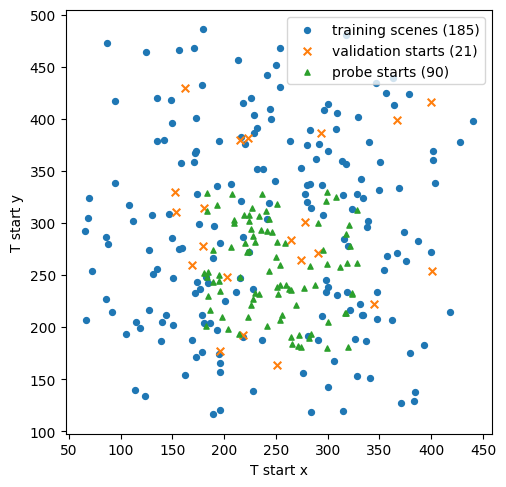

In [8]:
def start_states(split):
    return torch.load(ROOT / "data/pusht_noise" / split / "states.pth", map_location="cpu")


def nearest_scene_distance(starts, scenes):
    # T error between each start and its closest training scene.
    return np.array([physical_errors(scenes[:, 2:5], start[2:5])[2].min() for start in starts])


train_states = start_states("train")
train_starts = train_states[:, 0].numpy().round(1)
scenes, scene_of, episodes_per_scene = np.unique(train_starts, axis=0, return_inverse=True, return_counts=True)
val_starts = start_states("val")[:, 0].numpy()
probe_starts = np.stack([task["start"] for task in tasks])
others = [np.delete(scenes, index, axis=0) for index in range(len(scenes))]

display(pd.Series({
    "training episodes": len(train_starts),
    "distinct scenes": len(scenes),
    "median episodes per scene": np.median(episodes_per_scene),
    "fewest / most episodes per scene": f"{episodes_per_scene.min()} / {episodes_per_scene.max()}",
    "scenes in the first 2,000 episodes": len(np.unique(scene_of[:2000])),
    "scenes in the 21 spaced episodes (step 2)": len(np.unique(scene_of[spaced])),
    "scenes in the first 21 episodes": len(np.unique(scene_of[:21])),
    "median distance to nearest scene: another training scene": np.median([nearest_scene_distance(scenes[i : i + 1], others[i])[0] for i in range(len(scenes))]).round(1),
    "median distance to nearest scene: validation start": np.median(nearest_scene_distance(val_starts, scenes)).round(1),
    "median distance to nearest scene: probe start": np.median(nearest_scene_distance(probe_starts, scenes)).round(1),
}).to_frame("value"))

same_scene = train_states[:21, 50, 2:4].numpy()
print(f"T position 50 frames in, across the first 21 episodes (one scene): sd {same_scene.std(axis=0).round(1)} pixels")

figure, axis = plt.subplots(figsize=(5.5, 5.5))
axis.scatter(*scenes[:, 2:4].T, s=18, label=f"training scenes ({len(scenes)})")
axis.scatter(*val_starts[:, 2:4].T, s=30, marker="x", label="validation starts (21)")
axis.scatter(*probe_starts[:, 2:4].T, s=14, marker="^", label=f"probe starts ({len(probe_starts)})")
axis.set_xlabel("T start x")
axis.set_ylabel("T start y")
axis.legend()
plt.show()

Frames from different episodes are labelled 24 (max_gap) in training, because they have nothing to do with each other. If two different episodes come from the same scene, what does the cost say?

In [10]:
# The first 21 episodes are all from the same scene
one_scene = recorded_pairs("train", range(21))
pd.Series({
    "different scenes (training)": recorded["train"][2],
    "same scene (training)": one_scene[2],
    "validation": recorded["val"][2],
}).round(2).to_frame("mean prediction for frames from different episodes")

,mean prediction for frames from different episodes
different scenes (training),22.77
same scene (training),13.09
validation,22.16


- The 18,685 episodes are 185 scenes with exactly 101 copies each. Copies barely differ: the T's position 50 frames in varies by about 0.3 pixels across them. The training data is effectively 185 trajectories.
- Starts are not out of range. Validation and probe starts are about as close to their nearest training scene (29.7 and 33.4) as training scenes are to each other (30.2). The scatter plot shows the same thing, so the problem is not unfamiliar start positions.
- Same-scene frames get low predictions. Frames from different episodes of one scene score 13, against 23 for different scenes. The cost is tracking position along a known path, which is what the copies teach it.

Hypothesis: Each scene gives one path, so the cost has mostly seen states on 185 demonstration paths. Probe candidates come from random actions, so they are likely off those paths.

## Step 4: Is it worse everywhere, or only near the goal?

Compare `rank_all` (all 64 candidates) with `rank_near` (the 16 with the lowest T error).

The planner keeps only the lowest-cost candidate, so it needs to separate good candidates from slightly better ones. A cost can sort good from terrible and still fail at that. If `rank_all` is level but `rank_near` is much lower, this is that failure.

In [11]:
compare(["rank_all", "rank_near"])

,mse,temporal,favors temporal by,95% low,95% high,banks favoring temporal
metric,,,,,,
rank_all,0.532,0.503,-0.029,-0.100,0.034,0 of 3
rank_near,0.682,0.490,-0.192,-0.282,-0.099,0 of 3


Over all 64 candidates, temporal is close to MSE (0.50 vs 0.53). Among the 16 best it is clearly worse (0.49 vs 0.68), in all three banks. So it can sort good from bad but not good from slightly better. We saw some artifacts of this in Step 2 with the one-step ordering.

## Step 5: Does the score follow the T or the agent?

The goal photo's agent is in a random place. A candidate whose agent happens to be near it looks closer to the goal, even if its T is no better. We want the score to follow the T.

To check this, for each photo we fit a straight line that predicts the cost from both the `t_error` and the `agent_distance` at once:

$$z(\text{cost}) \approx \texttt{t\_weight} \cdot z(\text{T error}) + \texttt{agent\_weight} \cdot z(\text{agent distance})$$

$z(\cdot)$ here denotes normalize (z-score). That puts MSE and temporal on the same scale, since their raw units are unrelated.

- `t_weight`: how much the cost rises, in standard deviations, when T error rises by one standard deviation and agent distance stays fixed. This is what we want to be large.
- `agent_weight`: the same for agent distance, with T error fixed. This is the "agent influence" and we want it small.
- `r2`: the share of the cost's variation that the two together explain. The rest is something else, including noise.

The example below shows the raw data behind one such fit.

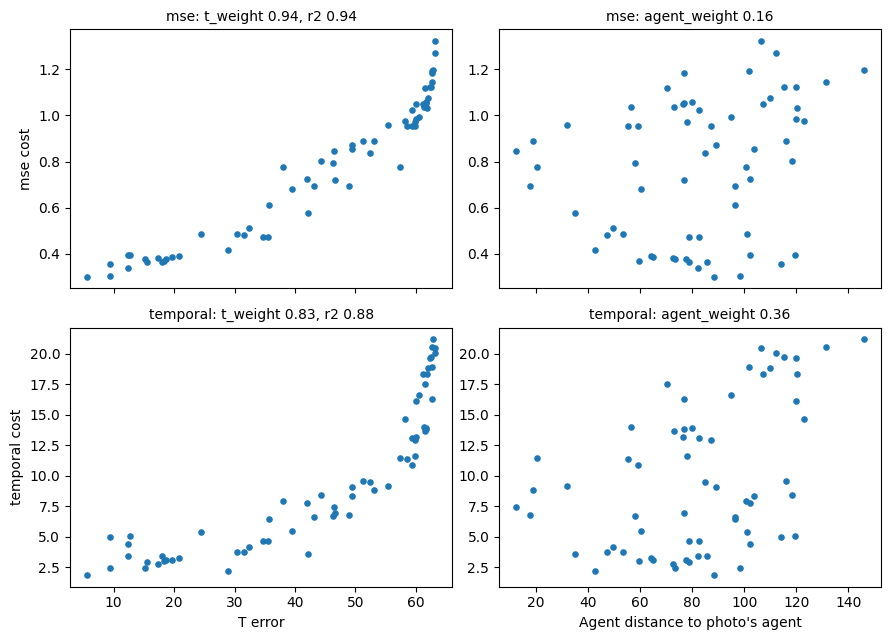

In [12]:
figure, axes = plt.subplots(2, 2, figsize=(9, 6.5), sharex="col")
poses, agents, goal_pose = example["poses"], example["agents"], example["goal_pose"]
t_err = physical_errors(poses, goal_pose)[2]
agent_distance = np.linalg.norm(agents - example["photo_agents"]["random_agent"][0], axis=1)
for row, method in enumerate(METHODS):
    costs = example["costs"]["predicted", "random_agent", method][:, 0]
    fit = grade_photo(costs, poses, agents, goal_pose, example["photo_agents"]["random_agent"][0])
    axes[row, 0].scatter(t_err, costs, s=14)
    axes[row, 1].scatter(agent_distance, costs, s=14)
    axes[row, 0].set_ylabel(f"{method} cost")
    axes[row, 0].set_title(f"{method}: t_weight {fit['t_weight']:.2f}, r2 {fit['r2']:.2f}", fontsize=10)
    axes[row, 1].set_title(f"{method}: agent_weight {fit['agent_weight']:.2f}", fontsize=10)
axes[1, 0].set_xlabel("T error")
axes[1, 1].set_xlabel("Agent distance to photo's agent")
plt.tight_layout()
plt.show()

Each dot is one candidate for one goal photo. A single photo proves little, so the table averages the same fit over all 720 photos.

In [13]:
compare(["t_weight", "agent_weight", "r2"], lower_is_better=("agent_weight",))

,mse,temporal,favors temporal by,95% low,95% high,banks favoring temporal
metric,,,,,,
t_weight,0.646,0.519,-0.127,-0.198,-0.052,0 of 3
agent_weight,0.353,0.200,0.153,0.090,0.223,3 of 3
r2,0.719,0.586,-0.133,-0.181,-0.087,0 of 3


**What we see.** `agent_weight` is lower than MSE's (0.20 vs 0.35), so the agent's position moves the temporal score less, which is the behavior we want.

However, `t_weight` is also lower than it is for MSE (by around 0.13) and `r2` is lower too (by around 0.12). Then more of the temporal score is explained by an external factor - neither the T nor the agent. However, the upside is that the agent is not what decides the cost.

## Step 6: Is it failing because it sees predicted features?

The cost was trained on features of real frames, but in planning it scores features the world model predicts. So we score the same candidates both ways, using `actual` features for the second.

If regret falls for `actual`, the shift to predicted features is the main problem.

In [14]:
pd.concat({source: compare(["regret", "rank_near"], source=source) for source in ("predicted", "actual")})

mse  temporal  favors temporal by  95% low  95% high  \
          metric                                                              
predicted regret     7.295    10.408              -3.114   -6.595     0.889   
          rank_near  0.682     0.490              -0.192   -0.282    -0.099   
actual    regret     3.927     9.956              -6.029   -9.399    -2.705   
          rank_near  0.661     0.499              -0.162   -0.249    -0.073   

                    banks favoring temporal  
          metric                             
predicted regret                     1 of 3  
          rank_near                  0 of 3  
actual    regret                     0 of 3  
          rank_near                  0 of 3

Temporal barely changes with real features, so predicted features are not its problem. MSE improves a lot (7.3 to 3.9), so the world model's prediction error is costing MSE more than temporal. Temporal's weakness comes from the cost itself.

## Step 7: Would it work with the agent in the right place?

Replace the 8 normal goal photos with the agent-matched photo: same target T, but the agent sits where the best candidate's agent ended up. This is cheating, because the planner could never have this photo. We do this only as a test.

If the agent mismatch is temporal's specific weakness, it should catch up with MSE here. If it stays behind, the problem is elsewhere.

`agreement` is missing here because there is only one photo.

In [15]:
pd.concat({goal: compare(["regret", "success", "rank_near"], goal=goal) for goal in ("random_agent", "matched_agent")})

mse  temporal  favors temporal by  95% low  \
              metric                                                    
random_agent  regret     7.295    10.408              -3.114   -6.595   
              success    0.806     0.640              -0.165   -0.264   
              rank_near  0.682     0.490              -0.192   -0.280   
matched_agent regret     1.507     5.102              -3.595   -6.755   
              success    0.944     0.833              -0.111   -0.200   
              rank_near  0.784     0.581              -0.203   -0.288   

                         95% high banks favoring temporal  
              metric                                       
random_agent  regret        0.889                  1 of 3  
              success      -0.060                  0 of 3  
              rank_near    -0.096                  0 of 3  
matched_agent regret       -1.035                  0 of 3  
              success      -0.033                  0 of 3  
              rank_near    -0.123                  0 of 3

Matching the agent helps both costs a lot, but temporal stays about as far behind (regret 5.1 vs 1.5, difference −3.6). The agent mismatch hurts both costs, and removing it doesn't close the gap, so the goal photo is not temporal's specific weakness.

## Summary

| Step | Question | Answer |
|---|---|---|
| 1 | Is the gap visible? | Yes on success and agreement. Less certain on regret |
| 2 | Does it count steps on unseen episodes? | Worse than on training episodes, moderately. Not sharp at one step even on training episodes |
| 3 | How varied is the data? | **185 scenes, not 18,685 independent episodes.** New starts are not out of range |
| 4 | Worse everywhere or near the goal? | Near the goal, in all three banks |
| 5 | T or agent? | Follows the agent less than MSE, but the T less too. Not the cause |
| 6 | Predicted features? | Not the cause |
| 7 | Goal photo's agent? | Hurts both costs equally. Not specific to temporal |

The cost can't separate good candidates from slightly better ones, and its training data contains only 185 distinct paths. The first part is measured. The link between them is a hypothesis.

Next steps to try:

1. Hold out whole scenes for validation, and spread any subset across scenes.
2. Test whether off-path data helps, by training on rollouts with varied actions and starts like the ones the planner actually scores.
3. Train for short-gap precision, since one model step is the scale that matters in the probe.

These results come from three dev banks and one trained model. Intervals over three banks are coarse. Step 2 uses 21 episodes per split, and step 5 is a simple straight-line fit.